# Figure 2: Bioactivity Prediction Accuracy

Compares bioactivity prediction accuracy across embedding modalities (co-embedding, GNEprop, Morgan Fingerprints) using partial AUROC, with paired statistical testing across seeds.

This notebook generates:
1. Bar plot comparing partial AUROC across representation types and classifiers

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
from collections import defaultdict

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import wilcoxon

from phenocompass.data.dataset import FastH5DatasetJUMP
from phenocompass.data.datamodule import MultiInput_DataModule

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

# --- Output directories ---
BASE_DIR = str(REPO_ROOT)
DATA_DIR = os.path.join(BASE_DIR, "data", "bioactivity_predictions")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "bioactivity_predictions")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = False

# --- Matplotlib / font configuration ---
setup_publication_style(BASE_DIR)

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'haiku'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Helper Classes and Functions

In [2]:
# --- Helper Classes (from source notebook) ---

class BioActivityPredictor:
    def __init__(self, model_type, dmso_x=None):
        self.model_type = model_type
        if self.model_type == "logistic_regression":
            self.model = LogisticRegression(max_iter=1000, class_weight="balanced")
        elif self.model_type == "knn_classifier":
            self.model = KNeighborsClassifier(n_neighbors=10, metric="cosine")
        elif self.model_type == "knn_classifier_euclidean":
            self.model = KNeighborsClassifier(n_neighbors=10, metric="euclidean")
        else:
            raise ValueError("Invalid model type")

    def fit(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict_proba(X)[:, 1]


# --- Consolidated evaluation function ---

def run_evaluation(dataset, y_true_df, model_type_list, representation_type,
                   struct_data=None, p_thresh=0.01,
                   representations_dict=None, dmso_modality="morph"):
    """
    Run bioactivity prediction evaluation for a given representation type.
    Results are cached to DATA_DIR using the load-or-compute pattern.
    """
    holdout_path = "none"
    holdout_to = "test"
    dmso_smiles = "CS(C)=O"

    all_results = {}

    for model_type in model_type_list:
        if representation_type == "coembedding":
            file_name = "bioactivity_predictions.{}.univariate_metrics_exclude_dmso.fdr{}.csv".format(
                model_type, p_thresh)
        elif representation_type == "gneprop":
            file_name = "bioactivity_predictions.gneprop_{}.univariate_metrics_exclude_dmso.fdr{}.csv".format(
                model_type, p_thresh)
        elif representation_type == "mf":
            file_name = "bioactivity_predictions.mf_{}.univariate_metrics_exclude_dmso.fdr{}.csv".format(
                model_type, p_thresh)
        else:
            raise ValueError("Unknown representation_type: {}".format(representation_type))

        cache_path = os.path.join(DATA_DIR, file_name)

        if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
            print("Loading cached results")
            results_df = pd.read_csv(cache_path)
        else:
            print("Generating results for: {} - {}".format(representation_type, model_type))
            results_dict = defaultdict(list)

            for seed in tqdm(range(6)):
                mod = MultiInput_DataModule(
                    dataset, split_sizes=(0.90, 0.05, 0.05),
                    split_type='index_predetermined',
                    holdout_notion="inchi", holdout_to=holdout_to,
                    holdout=holdout_path, seed=seed, verbose=False)
                mod.setup('stage')

                train_smiles = [n for n in mod.train_dataset.ids if n != dmso_smiles]
                test_smiles = [n for n in mod.test_dataset.ids if n != dmso_smiles]

                train_y = y_true_df.loc[train_smiles]["label"].values
                test_y = y_true_df.loc[test_smiles]["label"].values

                if representation_type == "coembedding":
                    for model_idx in [0, 1]:
                        morph_df = representations_dict[
                            "coembedding_{}_{}_{}" .format(model_idx, dmso_modality, seed)]
                        local_struct_df = representations_dict[
                            "coembedding_{}_{}_{}" .format(model_idx, "struct", seed)]

                        model = BioActivityPredictor(
                            model_type=model_type,
                            dmso_x=morph_df.loc[dmso_smiles].values)
                        train_X = local_struct_df.loc[train_smiles].values
                        test_X = local_struct_df.loc[test_smiles].values

                        model.fit(train_X, train_y)
                        pred_y = model.predict(test_X)

                        results_dict["seed"].append(seed)
                        results_dict["model_idx"].append(model_idx)
                        results_dict["model_type"].append(model_type)
                        results_dict["auroc"].append(roc_auc_score(test_y, pred_y))
                        for fpr in [0.01, 0.05, 0.1]:
                            results_dict["partial_auroc_fpr{}".format(fpr)].append(
                                roc_auc_score(test_y, pred_y, max_fpr=fpr))
                        results_dict["ap"].append(average_precision_score(test_y, pred_y))
                        results_dict["ap_baseline"].append(test_y.mean())
                else:
                    model = BioActivityPredictor(model_type=model_type)
                    train_X = struct_data.loc[train_smiles].values
                    test_X = struct_data.loc[test_smiles].values

                    model.fit(train_X, train_y)
                    pred_y = model.predict(test_X)

                    results_dict["seed"].append(seed)
                    results_dict["model_idx"].append(0)
                    results_dict["model_type"].append(model_type)
                    results_dict["auroc"].append(roc_auc_score(test_y, pred_y))
                    for fpr in [0.01, 0.05, 0.1]:
                        results_dict["partial_auroc_fpr{}".format(fpr)].append(
                            roc_auc_score(test_y, pred_y, max_fpr=fpr))
                    results_dict["ap"].append(average_precision_score(test_y, pred_y))
                    results_dict["ap_baseline"].append(test_y.mean())

            results_df = pd.DataFrame(results_dict)
            results_df.to_csv(cache_path, index=False)
            print("Saved results")

        all_results[model_type] = results_df

    return all_results


# --- Label mapping and plotting function ---

MODEL_NAME_DICT = {
    "logistic_regression_0": "PhenoCompass\n(Curated Features)\nEmbeddings + Logistic Regression",
    "logistic_regression_1": "PhenoCompass\n(GNEprop)\nEmbeddings + Logistic Regression",
    "knn_classifier_0": "PhenoCompass\n(Curated Features)\nEmbeddings + kNN Classifier",
    "knn_classifier_1": "PhenoCompass\n(GNEprop)\nEmbeddings + kNN Classifier",
    "mf_logistic_regression": "Morgan\nFingerprints + Logistic Regression",
    "gneprop_logistic_regression": "GNEprop\nEmbeddings + Logistic Regression",
    "mf_knn_classifier": "Morgan\nFingerprints + kNN Classifier",
    "gneprop_knn_classifier_euclidean": "GNEprop\nEmbeddings + kNN Classifier",
}


def plot_accuracy_barplot(p_thresh, metric="partial_auroc_fpr0.1"):
    """Load cached results, create accuracy barplot, run Wilcoxon signed-rank tests, and save figure."""

    viz_model_type_list = [
        "logistic_regression", "knn_classifier",
        "mf_logistic_regression", "mf_knn_classifier",
        "gneprop_logistic_regression", "gneprop_knn_classifier_euclidean",
    ]

    results_df_list = []
    for model_type in viz_model_type_list:
        file_name = "bioactivity_predictions.{}.univariate_metrics_exclude_dmso.fdr{}.csv".format(
            model_type, p_thresh)
        file_path = os.path.join(DATA_DIR, file_name)
        df = pd.read_csv(file_path)
        df["model_type"] = model_type
        results_df_list.append(df)

    results_df = pd.concat(results_df_list)
    results_df["model_type"] = [
        "{}_{}".format(n, int(model_idx)) if "gneprop" not in n and "mf" not in n else n
        for n, model_idx in results_df[["model_type", "model_idx"]].values
    ]
    results_df["model_name"] = [MODEL_NAME_DICT[n] for n in results_df["model_type"]]
    results_df["classifier"] = ["kNN\nClassifier" if "knn" in n else "Logistic\nRegression"
                                for n in results_df["model_type"].values]
    results_df["representation"] = [n.split(" +")[0] for n in results_df["model_name"]]

    results_df = results_df.drop_duplicates()
    results_df.sort_values(["representation", "classifier"], inplace=True)

    plt.figure(figsize=(2., 1.25))
    ax = sns.barplot(y="representation", x=metric, data=results_df, hue="classifier",
                     capsize=0.2, errorbar=("se", 2), edgecolor="black", palette=["orange", "khaki"],
                     err_kws={"linewidth": 0.8}, linewidth=0.5)
    sns.stripplot(y="representation", x=metric, data=results_df, hue="classifier",
                  color="black", dodge=True, alpha=0.8, size=1.)
    plt.xlabel("Partial AUROC\n(max FPR = 0.1)")
    plt.ylabel("")
    plt.xlim([0.45, 0.75])
    plt.axvline(x=0.5, linestyle="--", color="black", linewidth=0.5)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles[0:2], labels[0:2], bbox_to_anchor=(0.5, -0.4),
               loc="upper center", ncol=2, frameon=False)

    fig_name = "Fig2_bioactivity_predictions.{}.univariate_metrics_exclude_dmso.fdr{}.pdf".format(
        metric, p_thresh)
    fig_path = os.path.join(FIGURE_DIR, fig_name)
    save_figure(fig_path, FORCE_RECOMPUTE)

    # --- Statistical tests (paired Wilcoxon signed-rank, exact p-values) ---
    print("\n--- Wilcoxon signed-rank tests ---")
    reference_name = "PhenoCompass\n(Curated Features)\nEmbeddings + Logistic Regression"
    ref_df = results_df[results_df["model_name"] == reference_name].sort_values("seed")
    ref_values = ref_df[metric].values

    stats_records = []
    for model_name in results_df["model_name"].unique():
        if "PhenoCompass" not in model_name:
            comp_df = results_df[results_df["model_name"] == model_name].sort_values("seed")
            comp_values = comp_df[metric].values
            comparison = "PhenoCompass vs {}".format(model_name.replace("\n", " "))

            result = wilcoxon(ref_values, comp_values, alternative="greater", method="exact")
            print("{}:\tstatistic={:.3f}, p={}".format(model_name, result.statistic, result.pvalue))
            stats_records.append({
                "comparison": comparison,
                "test": "wilcoxon_signed_rank",
                "statistic": result.statistic,
                "p_value": result.pvalue,
                "alternative": "greater",
            })

    stats_df = pd.DataFrame(stats_records)
    print("\n--- Combined Statistical Tests ---")
    print(stats_df.to_string(index=False))

    return results_df, stats_df

print("Helper classes and functions defined.")

Helper classes and functions defined.


## 3. Load Data and Configure Models

In [3]:
# --- 4a. Load bioactivity predictions and define labels ---
p_thresh = 0.01

bioactivity_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_bioactivity_predictions.tsv")
bioactivity_df = pd.read_csv(bioactivity_path, sep="\t")
bioactivity_df.index = bioactivity_df["Metadata_SMILES"].values

y_true_df = bioactivity_df.copy()
y_true_df["label"] = y_true_df["significant_bh"].astype(int)

In [4]:
# --- 4b. Load co-embedding dataset (for co-embedding and Morgan FP splits) ---
h5_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_dino_tvn.h5")
index_predetermined_file = os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_cluster_splits.pkl")

dataset_coembed = FastH5DatasetJUMP(
    h5_path, avg_morph_feat=True, index_predetermined_file=index_predetermined_file,
    ohe_batch=True, struct_ipt="fixed",
    fixed_struct_data=os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet"))

# --- 4c. Load co-embedding representations (6 seeds x 2 models x 3 modalities) ---
n_seeds = 6
representations_dict = {}

emb_dir = os.path.join(FINAL_DATA_DIR, "embeddings/coembedding")
model_prefix_list = ["combined_fp", "consistency_reg"]

for seed in tqdm(range(n_seeds)):
    for model_idx, model_prefix in enumerate(model_prefix_list):
        for modality in ["struct", "morph", "joint"]:
            file_name = "{}_seed{}_{}.parquet".format(model_prefix, seed, modality)
            key = "coembedding_{}_{}_{}" .format(model_idx, modality, seed)
            representations_dict[key] = pd.read_parquet(os.path.join(emb_dir, file_name))

# --- 4d. Load GNEprop dataset and embeddings ---
dataset_gneprop = FastH5DatasetJUMP(
    h5_path, avg_morph_feat=True, index_predetermined_file=index_predetermined_file,
    ohe_batch=False, struct_ipt="fixed",
    fixed_struct_data=os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet"))

gneprop_struct_df = pd.read_parquet(
    os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet"))

# --- 4e. Load Morgan Fingerprint vectors ---
mf_struct_df = pd.read_parquet(
    os.path.join(FINAL_DATA_DIR, "embeddings/structure/morgan_fingerprints.parquet"))
print("Loaded Morgan Fingerprints: shape {}".format(mf_struct_df.shape))

# --- 4f. Define model type lists ---
coembed_model_types = ["logistic_regression", "knn_classifier"]
gneprop_model_types = ["logistic_regression", "knn_classifier_euclidean"]
mf_model_types = ["logistic_regression", "knn_classifier"]

print("\nData loading complete.")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:32<00:00,  5.48s/it]


Loaded Morgan Fingerprints: shape (108836, 2048)

Data loading complete.


## 4. Evaluation

Run bioactivity prediction for all three representation types (co-embedding, GNEprop, Morgan FP) across multiple classifiers. Results are cached as CSV files to `DATA_DIR`.

In [5]:
# --- 5a. Co-embedding evaluation (All Compounds) ---
print("=" * 60)
print("Co-embedding evaluation (All Compounds)")
print("=" * 60)
coembed_results = run_evaluation(
    dataset=dataset_coembed,
    y_true_df=y_true_df,
    model_type_list=coembed_model_types,
    representation_type="coembedding",
    p_thresh=p_thresh,
    representations_dict=representations_dict,
    dmso_modality="morph")

# --- 5b. GNEprop evaluation ---
print("\n" + "=" * 60)
print("GNEprop evaluation")
print("=" * 60)
gneprop_results = run_evaluation(
    dataset=dataset_gneprop,
    y_true_df=y_true_df,
    model_type_list=gneprop_model_types,
    representation_type="gneprop",
    struct_data=gneprop_struct_df,
    p_thresh=p_thresh)

# --- 5c. Morgan Fingerprint evaluation ---
print("\n" + "=" * 60)
print("Morgan Fingerprint evaluation")
print("=" * 60)
mf_results = run_evaluation(
    dataset=dataset_coembed,
    y_true_df=y_true_df,
    model_type_list=mf_model_types,
    representation_type="mf",
    struct_data=mf_struct_df,
    p_thresh=p_thresh)

print("\nEvaluation complete.")

Co-embedding evaluation (All Compounds)
Loading cached results
Loading cached results

GNEprop evaluation
Loading cached results
Loading cached results

Morgan Fingerprint evaluation
Loading cached results
Loading cached results

Evaluation complete.


Generating bar plot
Figure already exists


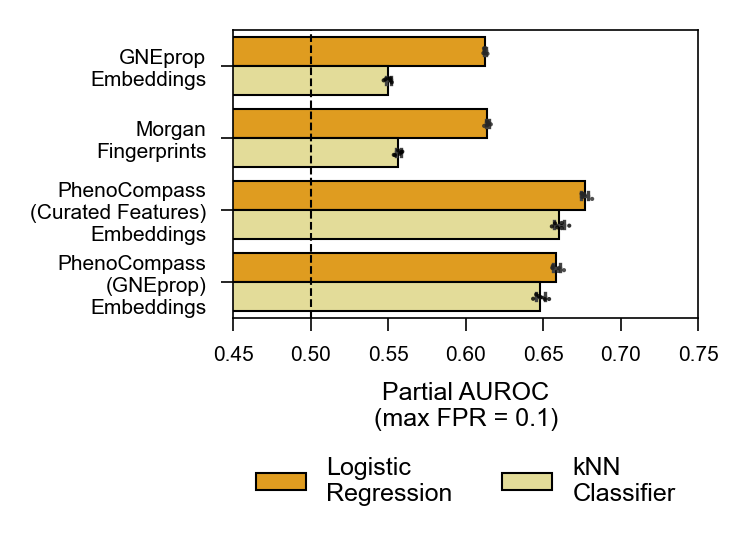


--- Wilcoxon signed-rank tests ---
GNEprop
Embeddings + Logistic Regression:	statistic=21.000, p=0.015625
GNEprop
Embeddings + kNN Classifier:	statistic=21.000, p=0.015625
Morgan
Fingerprints + Logistic Regression:	statistic=21.000, p=0.015625
Morgan
Fingerprints + kNN Classifier:	statistic=21.000, p=0.015625

--- Combined Statistical Tests ---
                                               comparison                 test  statistic  p_value alternative
 PhenoCompass vs GNEprop Embeddings + Logistic Regression wilcoxon_signed_rank       21.0 0.015625     greater
      PhenoCompass vs GNEprop Embeddings + kNN Classifier wilcoxon_signed_rank       21.0 0.015625     greater
PhenoCompass vs Morgan Fingerprints + Logistic Regression wilcoxon_signed_rank       21.0 0.015625     greater
     PhenoCompass vs Morgan Fingerprints + kNN Classifier wilcoxon_signed_rank       21.0 0.015625     greater

Visualization complete.


In [6]:
# --- 5d. Visualize results ---
print("Generating bar plot")
results_all, stats_all = plot_accuracy_barplot(p_thresh=p_thresh, metric="partial_auroc_fpr0.1")
print("\nVisualization complete.")

## 5. Summary

Summary of mean metrics across models.

In [7]:
# --- Build summary table ---
summary_df = results_all.copy()
summary_metrics = summary_df.groupby(["model_name"]).agg({
    "partial_auroc_fpr0.1": "mean",
}).round(4)

print("Summary of mean metrics across all models:")
summary_metrics

Summary of mean metrics across all models:


,partial_auroc_fpr0.1
model_name,
GNEprop\nEmbeddings + Logistic Regression,0.6123
GNEprop\nEmbeddings + kNN Classifier,0.5500
Morgan\nFingerprints + Logistic Regression,0.6140
Morgan\nFingerprints + kNN Classifier,0.5565
PhenoCompass\n(Curated Features)\nEmbeddings + Logistic Regression,0.6766
PhenoCompass\n(Curated Features)\nEmbeddings + kNN Classifier,0.6604
PhenoCompass\n(GNEprop)\nEmbeddings + Logistic Regression,0.6585
PhenoCompass\n(GNEprop)\nEmbeddings + kNN Classifier,0.6481


In [8]:
# Save figure source data for manuscript reproducibility
fig_data_path = os.path.join(FIGURE_DIR, "Fig2_bioactivity_predictions_barplot_data.tsv")
save_figure_data(summary_df, fig_data_path, FORCE_RECOMPUTE)

# Save Wilcoxon rank-sum test results
stats_path = os.path.join(FIGURE_DIR, "Fig2_bioactivity_predictions_stats.tsv")
save_figure_data(stats_all, stats_path, FORCE_RECOMPUTE)

Figure data already exists
Figure data already exists
